In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

labels = ['A', 'B', 'C', 'D', 'E']

S = np.array([
    [1.0, 0.8, 0.6, 0.2, 0.3],
    [0.8, 1.0, 0.7, 0.3, 0.4],
    [0.6, 0.7, 1.0, 0.5, 0.2],
    [0.2, 0.3, 0.5, 1.0, 0.7],
    [0.3, 0.4, 0.2, 0.7, 1.0]
], dtype=float)

similarities = S.flatten()
median_pref = np.median(similarities)
np.fill_diagonal(S, median_pref)

print("Preference set to:", median_pref)
print("Similarity Matrix S:")
df_S = pd.DataFrame(S, index=labels, columns=labels)
print(df_S.to_string())

Preference set to: 0.6
Similarity Matrix S:
     A    B    C    D    E
A  0.6  0.8  0.6  0.2  0.3
B  0.8  0.6  0.7  0.3  0.4
C  0.6  0.7  0.6  0.5  0.2
D  0.2  0.3  0.5  0.6  0.7
E  0.3  0.4  0.2  0.7  0.6


In [ ]:
def responsibility_update(S, A, R_old=None, damping=0.5):
    """
    Cập nhật Responsibility với damping
    R(i,k) = S(i,k) - max_{k' ≠ k} [A(i,k') + S(i,k')]
    """
    AS = A + S
    n = len(S)

    max_vals = np.max(AS, axis=1)
    max_indices = np.argmax(AS, axis=1)

    second_max_vals = np.full(n, -np.inf)
    for i in range(n):
        temp = AS[i].copy()
        temp[max_indices[i]] = -np.inf
        second_max_vals[i] = np.max(temp)

    new_R = np.zeros_like(S)
    for i in range(n):
        for k in range(n):
            if k == max_indices[i]:
                new_R[i, k] = S[i, k] - second_max_vals[i]
            else:
                new_R[i, k] = S[i, k] - max_vals[i]

    if R_old is not None:
        return damping * R_old + (1 - damping) * new_R
    return new_R

def availability_update(R, A_old=None, damping=0.5):
    n = len(R)
    R_pos = np.maximum(R, 0)

    new_A = np.zeros_like(R)

    for k in range(n):
        new_A[k, k] = np.sum(R_pos[:, k]) - R_pos[k, k]

    for i in range(n):
        for k in range(n):
            if i != k:
                new_A[i, k] = min(0, R[k, k] + (new_A[k, k] - R_pos[i, k]))

    if A_old is not None:
        return damping * A_old + (1 - damping) * new_A
    return new_A

In [ ]:
def print_matrix(M, title, labels):
    print(f"\n{title}")
    df = pd.DataFrame(M.round(3), index=labels, columns=labels)
    print(df.to_string())

def affinity_propagation(S, labels, max_iter=50, damping=0.5, conv_iter=10, verbose=True):

    n = len(S)
    R = np.zeros_like(S)
    A = np.zeros_like(S)

    history = []
    exemplar_history = []

    print("BẮT ĐẦU THUẬT TOÁN AFFINITY PROPAGATION")
    print("=" * 60)

    for t in range(max_iter):
        R_old, A_old = R.copy(), A.copy()

        R = responsibility_update(S, A, R_old, damping)
        A = availability_update(R, A_old, damping)

        E = R + A

        exemplars = [i for i in range(n) if E[i, i] > 0]

        history.append({
            'iteration': t + 1,
            'R': R.copy(),
            'A': A.copy(),
            'E': E.copy(),
            'exemplars': exemplars.copy()
        })
        exemplar_history.append(len(exemplars))

        if verbose and t < 3:
            print(f"\n--- Vòng lặp {t + 1} ---")
            print_matrix(R, f"Responsibility (R) - Damping={damping}", labels)
            print_matrix(A, f"Availability (A) - Damping={damping}", labels)
            print_matrix(E, f"Exemplar (E) - Damping={damping}", labels)
            print(f"Exemplars: {[labels[i] for i in exemplars]}")

        if t >= conv_iter:
            recent_exemplars = [h['exemplars'] for h in history[-conv_iter:]]
            if all(ex == recent_exemplars[0] for ex in recent_exemplars):
                if verbose:
                    print(f"\n*** HỘI TỤ SAU {t+1} VÒNG LẶP ***")
                break

    final_E = history[-1]['E']
    clusters = {}
    for i, label in enumerate(labels):
        exemplar_idx = np.argmax(final_E[i, :])
        clusters[label] = labels[exemplar_idx]

    return history, clusters, exemplar_history

history, clusters, exemplar_history = affinity_propagation(
    S, labels, max_iter=20, damping=0.5, conv_iter=3, verbose=True
)

BẮT ĐẦU THUẬT TOÁN AFFINITY PROPAGATION

--- Vòng lặp 1 ---

Responsibility (R) - Damping=0.5
      A     B     C     D     E
A -0.10  0.10 -0.10 -0.30 -0.25
B  0.05 -0.10 -0.05 -0.25 -0.20
C -0.05  0.05 -0.05 -0.10 -0.25
D -0.25 -0.20 -0.10 -0.05  0.05
E -0.20 -0.15 -0.25  0.05 -0.05

Availability (A) - Damping=0.5
       A      B      C      D      E
A  0.025 -0.025 -0.025  0.000  0.000
B -0.050  0.075 -0.025  0.000  0.000
C -0.025  0.000  0.000  0.000  0.000
D -0.025  0.000 -0.025  0.025 -0.025
E -0.025  0.000 -0.025 -0.025  0.025

Exemplar (E) - Damping=0.5
       A      B      C      D      E
A -0.075  0.075 -0.125 -0.300 -0.250
B  0.000 -0.025 -0.075 -0.250 -0.200
C -0.075  0.050 -0.050 -0.100 -0.250
D -0.275 -0.200 -0.125 -0.025  0.025
E -0.225 -0.150 -0.275  0.025 -0.025
Exemplars: []

--- Vòng lặp 2 ---

Responsibility (R) - Damping=0.5
       A      B      C      D      E
A -0.138  0.138 -0.138 -0.438 -0.363
B  0.088 -0.125 -0.050 -0.350 -0.275
C -0.075  0.075 -0.075 -0.150 -

In [ ]:
final_result = history[-1]
final_exemplars = final_result['exemplars']

print("\n" + "="*60)
print("KẾT QUẢ CUỐI CÙNG")
print("="*60)
print(f"Số exemplars: {len(final_exemplars)}")
print(f"Các exemplars: {[labels[i] for i in final_exemplars]}")

clusters = {}
for i, label in enumerate(labels):
    if i in final_exemplars:
        clusters[label] = label
    else:
        exemplar_scores = []
        for k in final_exemplars:
            exemplar_scores.append((k, final_result['E'][i, k]))

        best_exemplar = max(exemplar_scores, key=lambda x: x[1])[0]
        clusters[label] = labels[best_exemplar]

print(f"\nPhân cụm ĐÚNG:")
for point, exemplar in clusters.items():
    print(f"  {point} → {exemplar}")

print(f"\nMa trận E (R + A):")
E_df = pd.DataFrame(final_result['E'].round(3), index=labels, columns=labels)
print(E_df.to_string())

print(f"\nĐường chéo của E (quyết định exemplar):")
for i, label in enumerate(labels):
    print(f"  {label}: {final_result['E'][i, i]:.3f} {'(EXEMPLAR)' if final_result['E'][i, i] > 0 else ''}")


KẾT QUẢ CUỐI CÙNG
Số exemplars: 1
Các exemplars: ['B']

Phân cụm ĐÚNG:
  A → B
  B → B
  C → B
  D → B
  E → B

Ma trận E (R + A):
       A      B      C      D      E
A -0.105  0.120 -0.240 -0.534 -0.440
B -0.097  0.112 -0.148 -0.441 -0.348
C -0.180  0.094 -0.094 -0.187 -0.469
D -0.517 -0.337 -0.230 -0.001  0.001
E -0.423 -0.243 -0.512  0.001 -0.001

Đường chéo của E (quyết định exemplar):
  A: -0.105 
  B: 0.112 (EXEMPLAR)
  C: -0.094 
  D: -0.001 
  E: -0.001 


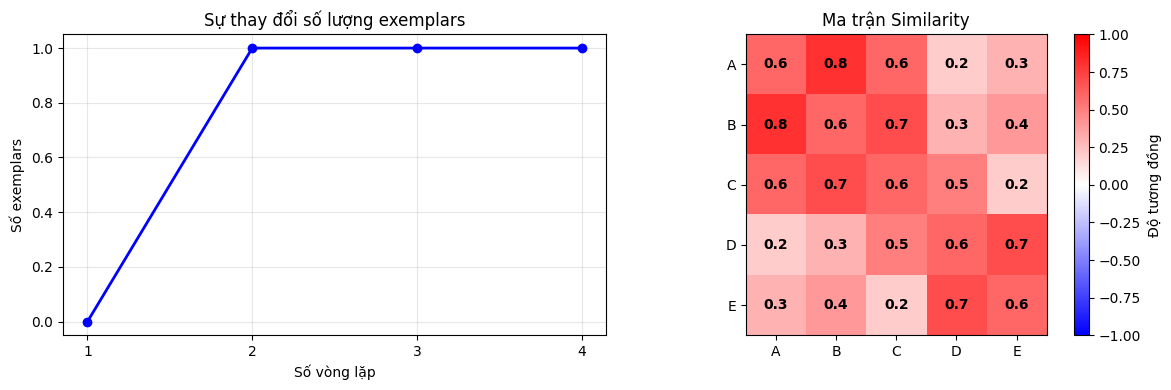

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
iterations = [h['iteration'] for h in history]
num_exemplars = [len(h['exemplars']) for h in history]

plt.plot(iterations, num_exemplars, 'bo-', linewidth=2, markersize=6)
plt.xlabel('Số vòng lặp')
plt.ylabel('Số exemplars')
plt.title('Sự thay đổi số lượng exemplars')
plt.grid(True, alpha=0.3)
plt.xticks(iterations)

plt.subplot(1, 2, 2)
cmap = LinearSegmentedColormap.from_list('custom', ['blue', 'white', 'red'])
plt.imshow(S, cmap=cmap, interpolation='nearest', vmin=-1, vmax=1)

for i in range(len(S)):
    for j in range(len(S)):
        plt.text(j, i, f'{S[i,j]:.1f}',
                ha='center', va='center', fontweight='bold')

plt.colorbar(label='Độ tương đồng')
plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
plt.title('Ma trận Similarity')

plt.tight_layout()
plt.show()

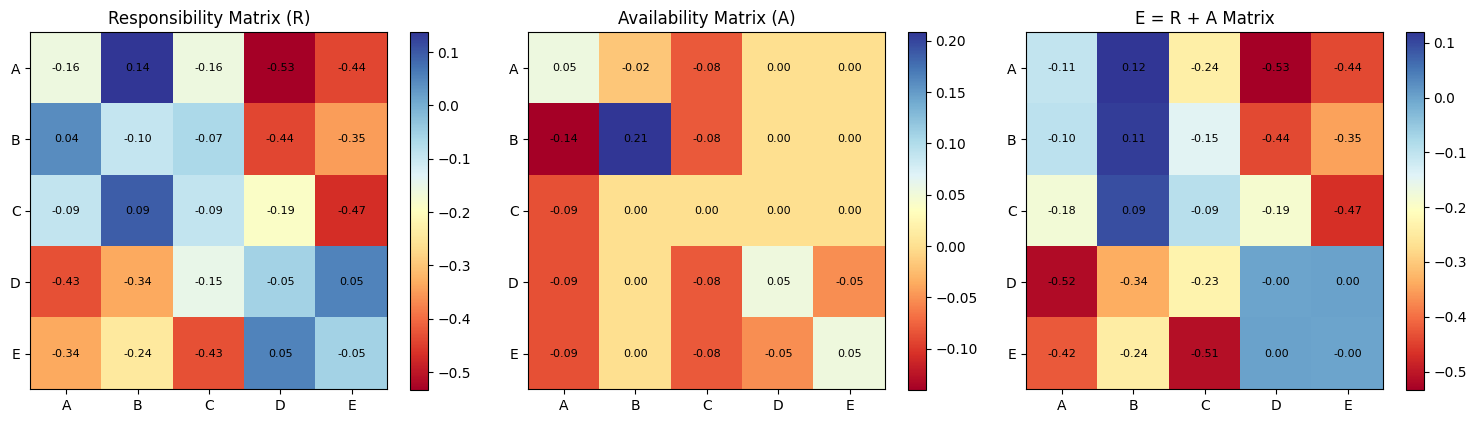

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

im1 = axes[0].imshow(final_result['R'], cmap='RdYlBu', interpolation='nearest')
for i in range(len(labels)):
    for j in range(len(labels)):
        axes[0].text(j, i, f'{final_result["R"][i,j]:.2f}',
                    ha='center', va='center', fontsize=8)
axes[0].set_xticks(range(len(labels)))
axes[0].set_yticks(range(len(labels)))
axes[0].set_xticklabels(labels)
axes[0].set_yticklabels(labels)
axes[0].set_title('Responsibility Matrix (R)')
plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(final_result['A'], cmap='RdYlBu', interpolation='nearest')
for i in range(len(labels)):
    for j in range(len(labels)):
        axes[1].text(j, i, f'{final_result["A"][i,j]:.2f}',
                    ha='center', va='center', fontsize=8)
axes[1].set_xticks(range(len(labels)))
axes[1].set_yticks(range(len(labels)))
axes[1].set_xticklabels(labels)
axes[1].set_yticklabels(labels)
axes[1].set_title('Availability Matrix (A)')
plt.colorbar(im2, ax=axes[1])

im3 = axes[2].imshow(final_result['E'], cmap='RdYlBu', interpolation='nearest')
for i in range(len(labels)):
    for j in range(len(labels)):
        axes[2].text(j, i, f'{final_result["E"][i,j]:.2f}',
                    ha='center', va='center', fontsize=8)
axes[2].set_xticks(range(len(labels)))
axes[2].set_yticks(range(len(labels)))
axes[2].set_xticklabels(labels)
axes[2].set_yticklabels(labels)
axes[2].set_title('E = R + A Matrix')
plt.colorbar(im3, ax=axes[2])

plt.tight_layout()
plt.show()

In [ ]:
print("THỬ NGHIỆM VỚI CÁC THAM SỐ KHÁC NHAU")
print("="*50)

damping_values = [0.5, 0.7, 0.9]
preference_values = [np.median(S), np.min(S), np.max(S)]

for damping in damping_values:
    for preference in preference_values:
        print(f"\n--- Damping: {damping}, Preference: {preference:.3f} ---")

        S_test = S.copy()
        np.fill_diagonal(S_test, preference)

        history_test, clusters_test, _ = affinity_propagation(
            S_test, labels, max_iter=20, damping=damping, conv_iter=3, verbose=False
        )

        final_exemplars_test = history_test[-1]['exemplars']
        print(f"Exemplars: {[labels[i] for i in final_exemplars_test]}")
        print(f"Clusters: {clusters_test}")

THỬ NGHIỆM VỚI CÁC THAM SỐ KHÁC NHAU

--- Damping: 0.5, Preference: 0.600 ---
BẮT ĐẦU THUẬT TOÁN AFFINITY PROPAGATION
Exemplars: ['B']
Clusters: {'A': 'B', 'B': 'B', 'C': 'B', 'D': 'E', 'E': 'D'}

--- Damping: 0.5, Preference: 0.200 ---
BẮT ĐẦU THUẬT TOÁN AFFINITY PROPAGATION
Exemplars: ['B', 'D']
Clusters: {'A': 'B', 'B': 'B', 'C': 'B', 'D': 'D', 'E': 'D'}

--- Damping: 0.5, Preference: 0.800 ---
BẮT ĐẦU THUẬT TOÁN AFFINITY PROPAGATION
Exemplars: ['C', 'D', 'E']
Clusters: {'A': 'A', 'B': 'A', 'C': 'C', 'D': 'D', 'E': 'E'}

--- Damping: 0.7, Preference: 0.600 ---
BẮT ĐẦU THUẬT TOÁN AFFINITY PROPAGATION
Exemplars: ['B']
Clusters: {'A': 'B', 'B': 'B', 'C': 'B', 'D': 'E', 'E': 'D'}

--- Damping: 0.7, Preference: 0.200 ---
BẮT ĐẦU THUẬT TOÁN AFFINITY PROPAGATION
Exemplars: []
Clusters: {'A': 'B', 'B': 'A', 'C': 'B', 'D': 'E', 'E': 'D'}

--- Damping: 0.7, Preference: 0.800 ---
BẮT ĐẦU THUẬT TOÁN AFFINITY PROPAGATION
Exemplars: ['C', 'D', 'E']
Clusters: {'A': 'A', 'B': 'A', 'C': 'C', 'D': 'D

### Thay đổi tham số Preferences

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def show_mat(M, labels, title, do_plot=True):
    df = pd.DataFrame(M.round(3), index=labels, columns=labels)
    print(f"\n{title}:\n{df.to_string()}\n")
    if do_plot:
        plt.figure(figsize=(3.2,3))
        plt.title(title)
        plt.imshow(M)
        plt.colorbar()
        plt.xticks(range(len(labels)), labels)
        plt.yticks(range(len(labels)), labels)
        plt.tight_layout()
        plt.show()

def upd_r(S, a):
    AS = a + S
    m1 = np.max(AS, axis=1)
    idx = np.argmax(AS, axis=1)
    m2 = np.full_like(m1, -np.inf)
    for i in range(AS.shape[0]):
        tmp = AS[i].copy()
        tmp[idx[i]] = -np.inf
        m2[i] = np.max(tmp)
    max_exc = np.zeros_like(AS)
    for i in range(AS.shape[0]):
        for k in range(AS.shape[1]):
            max_exc[i,k] = m2[i] if k == idx[i] else m1[i]
    return S - max_exc

def upd_a(r):
    rp = np.maximum(0, r)
    colsum = np.sum(rp, axis=0)
    n = r.shape[0]
    a = np.zeros_like(r)
    for k in range(n):
        a[k,k] = colsum[k] - rp[k,k]
        for i in range(n):
            if i == k:
                continue
            others = colsum[k] - rp[i,k] - rp[k,k]
            a[i,k] = min(0.0, r[k,k] + others)
    return a

def assign(e):
    return np.argmax(e, axis=1)

def run_ap(S_in, pref=0.0, damp=0.5, max_it=50, conv_iter=10, labels=None,
           run_name="run", show_plots=False, show_every=1):
    n = S_in.shape[0]
    S = S_in.copy()
    np.fill_diagonal(S, pref)
    if labels is None:
        labels = [str(i) for i in range(n)]
    print(f"\n=== {run_name} : pref={pref}, damp={damp} ===")
    show_mat(S, labels, title=f"S (pref={pref})", do_plot=show_plots)

    r = np.zeros_like(S)
    a = np.zeros_like(S)
    history_ex = []

    for t in range(1, max_it+1):
        r_new = upd_r(S, a)
        r = damp * r + (1-damp) * r_new
        a_new = upd_a(r)
        a = damp * a + (1-damp) * a_new
        e = r + a

        if (t % show_every) == 0:
            print(f"--- Iter {t} ---")
            show_mat(r, labels, title=f"r (iter {t})", do_plot=show_plots)
            show_mat(a, labels, title=f"a (iter {t})", do_plot=show_plots)
            show_mat(e, labels, title=f"e=r+a (iter {t})", do_plot=show_plots)
            ex = np.where(np.diag(e) > 0)[0]
            print("exemplars indices (diag(e)>0):", list(ex))
            print("assignments (argmax e):", [labels[k] for k in assign(e)])
        else:
            ex = np.where(np.diag(e) > 0)[0]
        history_ex.append(tuple(ex))

        if t >= conv_iter:
            recent = history_ex[-conv_iter:]
            if all(x == recent[0] for x in recent):
                print(f"Converged (stable exemplars) at iteration {t}")
                break
    else:
        print("Reached max iterations without stable exemplar set.")

    ex_final = np.where(np.diag(e) > 0)[0]
    assign_final = assign(e)
    return {"S": S, "r": r, "a": a, "e": e, "exemplars": ex_final, "assign": assign_final}


s12, s13, s23 = 0.5, 0.2, 0.4
S0 = np.array([
    [0.0, s12, s13],
    [s12, 0.0, s23],
    [s13, s23, 0.0]
], dtype=float)
labels = ["1","2","3"]


res_high = run_ap(S0, pref=0.8, damp=0.5, max_it=30, conv_iter=5,
                  labels=labels, run_name="HIGH_PREF",
                  show_plots=False, show_every=1)

res_low  = run_ap(S0, pref=0.0, damp=0.5, max_it=30, conv_iter=5,
                  labels=labels, run_name="LOW_PREF",
                  show_plots=False, show_every=1)

print("\nSUMMARY HIGH_PREF exemplars:", [labels[i] for i in res_high["exemplars"]])
print("SUMMARY HIGH_PREF assignments:", [labels[i] for i in res_high["assign"]])
print("\nSUMMARY LOW_PREF exemplars:", [labels[i] for i in res_low["exemplars"]])
print("SUMMARY LOW_PREF assignments:", [labels[i] for i in res_low["assign"]])


=== HIGH_PREF : pref=0.8, damp=0.5 ===

S (pref=0.8):
     1    2    3
1  0.8  0.5  0.2
2  0.5  0.8  0.4
3  0.2  0.4  0.8

--- Iter 1 ---

r (iter 1):
      1     2    3
1  0.15 -0.15 -0.3
2 -0.15  0.15 -0.2
3 -0.30 -0.20  0.2


a (iter 1):
     1    2    3
1  0.0  0.0  0.0
2  0.0  0.0  0.0
3  0.0  0.0  0.0


e=r+a (iter 1):
      1     2    3
1  0.15 -0.15 -0.3
2 -0.15  0.15 -0.2
3 -0.30 -0.20  0.2

exemplars indices (diag(e)>0): [np.int64(0), np.int64(1), np.int64(2)]
assignments (argmax e): ['1', '2', '3']
--- Iter 2 ---

r (iter 2):
       1      2     3
1  0.225 -0.225 -0.45
2 -0.225  0.225 -0.30
3 -0.450 -0.300  0.30


a (iter 2):
     1    2    3
1  0.0  0.0  0.0
2  0.0  0.0  0.0
3  0.0  0.0  0.0


e=r+a (iter 2):
       1      2     3
1  0.225 -0.225 -0.45
2 -0.225  0.225 -0.30
3 -0.450 -0.300  0.30

exemplars indices (diag(e)>0): [np.int64(0), np.int64(1), np.int64(2)]
assignments (argmax e): ['1', '2', '3']
--- Iter 3 ---

r (iter 3):
       1      2      3
1  0.263 -0.263 -